# EDA: стоимость доставки (Olist)

Цель: понять целевую переменную `freight_value` и её связь с признаками **до** обучения моделей.

В конце есть ячейка «📝 Выводы»: заполни её сам после запуска. Формулировать выводы — главная часть EDA.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (10, 4)

# Путь указан относительно папки notebooks/. Поправь, если файл лежит иначе.
DATA_PATH = Path('../data/processed/joined_result.csv')
TARGET = 'freight_value'

In [2]:
df = pd.read_csv(DATA_PATH)

df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
print(df.shape)
df.head()

(112650, 22)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


## 1. Структура и «зерно» данных

Ожидаем: одна строка = один товар в заказе, дубликатов по `(order_id, order_item_id)` нет.

In [3]:
print('Строк:', len(df))
print('Дубликатов (order_id, order_item_id):', df.duplicated(['order_id', 'order_item_id']).sum())
print('Уникальных заказов:', df['order_id'].nunique())
print('Уникальных товаров:', df['product_id'].nunique())
print('Уникальных продавцов:', df['seller_id'].nunique())
df.dtypes

Строк: 112650
Дубликатов (order_id, order_item_id): 0
Уникальных заказов: 98666
Уникальных товаров: 32951
Уникальных продавцов: 3095


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                           str
order_delivered_carrier_date                str
order_delivered_customer_date               str
order_estimated_delivery_date               str
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date                         str
price                                   float64
freight_value                           float64
product_category_name                       str
product_name_lenght                     float64
product_description_lenght              float64
product_photos_qty                      float64
product_weight_g                        float64
product_length_cm                       float64
product_height_cm                       

## 2. Пропуски

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({'пропусков': missing, 'доля': (missing / len(df)).round(4)})

,пропусков,доля
order_delivered_customer_date,2454,0.0218
product_name_lenght,1603,0.0142
product_category_name,1603,0.0142
product_description_lenght,1603,0.0142
product_photos_qty,1603,0.0142
order_delivered_carrier_date,1194,0.0106
product_weight_g,18,0.0002
product_height_cm,18,0.0002
product_length_cm,18,0.0002
product_width_cm,18,0.0002


## 3. Целевая переменная

На что смотреть: насколько тяжёлый хвост, сколько нулей (бесплатная доставка), есть ли явные выбросы.

In [8]:
y = df[TARGET]
display(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print(f'Доля нулевой доставки: {(y == 0).mean():.2%}')
print(f'Асимметрия (skew): {y.skew():.2f}')

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
1%            4.419800
5%            7.780000
25%          13.080000
50%          16.260000
75%          21.150000
95%          45.120000
99%          84.520000
max         409.680000
Name: freight_value, dtype: float64

Доля нулевой доставки: 0.34%
Асимметрия (skew): 5.64


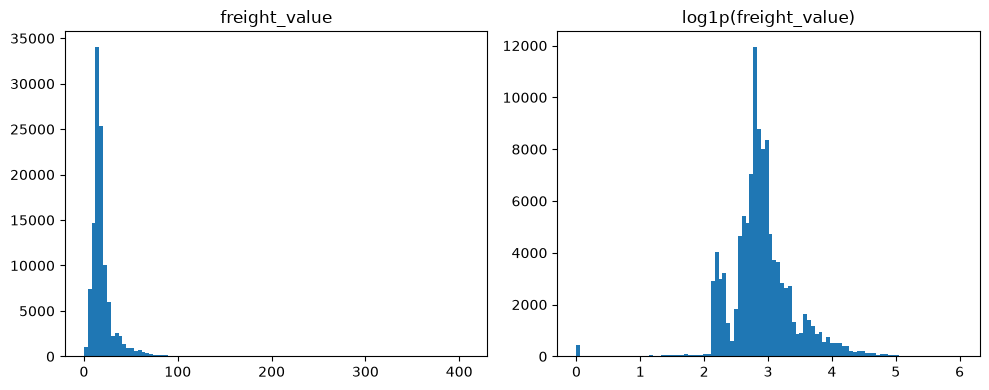

In [6]:
fig, axes = plt.subplots(1, 2)
axes[0].hist(y, bins=100)
axes[0].set_title(TARGET)
axes[1].hist(np.log1p(y), bins=100)
axes[1].set_title(f'log1p({TARGET})')
plt.tight_layout()
plt.show()

Распределение с тяжёлым правым хвостом. После log1p (ln(1 + x), так как ln(x) не определён в нуле). На логарифмической шкале видна ступенчатая структура: похоже на тарифную сетку. Около 0.4% строк — бесплатная доставка.

Самые дорогие доставки: это осмысленные значения (тяжёлые, крупные товары) или похоже на ошибки?

In [9]:
cols = ['price', TARGET, 'product_category_name', 'product_weight_g',
        'product_length_cm', 'product_height_cm', 'product_width_cm']
df.nlargest(10, TARGET)[cols]

,price,freight_value,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
57086,979.00,409.68,bebes,14675.0,55.0,64.0,52.0
84927,2338.08,375.28,utilidades_domesticas,30000.0,75.0,58.0,65.0
111396,2338.08,375.28,utilidades_domesticas,30000.0,75.0,58.0,65.0
17759,1149.00,339.59,utilidades_domesticas,25250.0,68.0,66.0,66.0
108354,1050.00,338.30,beleza_saude,30000.0,55.0,75.0,61.0
8180,1050.00,322.10,beleza_saude,30000.0,55.0,75.0,61.0
97319,1050.00,321.88,beleza_saude,30000.0,55.0,75.0,61.0
73592,990.00,321.46,construcao_ferramentas_construcao,30000.0,100.0,50.0,50.0
111784,3089.00,317.47,industria_comercio_e_negocios,11300.0,44.0,34.0,25.0
16654,1045.00,314.40,construcao_ferramentas_construcao,30000.0,100.0,50.0,50.0


## 4. Физические характеристики товара

Гипотеза: вес и габариты — главные драйверы стоимости доставки. Сначала проверим аномалии.

Объём здесь считается только для исследования. В пайплайне ему место в `features.py`.

In [10]:
phys = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
display(df[phys].describe())
print('Строк с весом = 0:', (df['product_weight_g'] == 0).sum())

eda = df.copy()
eda['volume_cm3'] = eda['product_length_cm'] * eda['product_height_cm'] * eda['product_width_cm']

,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112632.000000,112632.000000,112632.000000,112632.000000
mean,2093.672047,30.153669,16.593766,22.996546
std,3751.596884,16.153449,13.443483,11.707268
min,0.000000,7.000000,2.000000,6.000000
25%,300.000000,18.000000,8.000000,15.000000
50%,700.000000,25.000000,13.000000,20.000000
75%,1800.000000,38.000000,20.000000,30.000000
max,40425.000000,105.000000,105.000000,118.000000


Строк с весом = 0: 8


## 5. Связь таргета с числовыми признаками

Используем корреляцию Спирмена: она ранговая, поэтому устойчива к выбросам и ловит монотонные нелинейные связи.

In [11]:
num_cols = ['price', 'product_weight_g', 'volume_cm3', 'product_length_cm',
            'product_height_cm', 'product_width_cm', 'product_photos_qty',
            'product_name_lenght', 'product_description_lenght']
corr = eda[num_cols + [TARGET]].corr(method='spearman')[TARGET].drop(TARGET)
corr.sort_values(key=abs, ascending=False)

product_weight_g              0.446591
price                         0.434190
volume_cm3                    0.368587
product_length_cm             0.283799
product_height_cm             0.282375
product_width_cm              0.273765
product_description_lenght    0.116562
product_name_lenght           0.034341
product_photos_qty            0.010050
Name: freight_value, dtype: float64

Точек больше 100 тысяч, поэтому вместо scatter используем hexbin: цвет показывает плотность. Оси логарифмические.

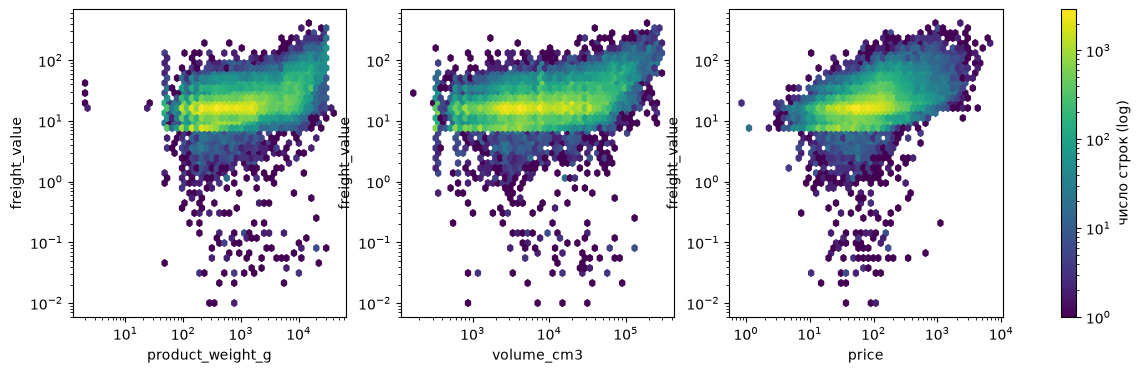

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['product_weight_g', 'volume_cm3', 'price']):
    d = eda[(eda[col] > 0) & (eda[TARGET] > 0)]
    hb = ax.hexbin(d[col], d[TARGET], gridsize=50, xscale='log', yscale='log',
                   bins='log', mincnt=1)
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
fig.colorbar(hb, ax=axes, label='число строк (log)')
plt.show()

## 6. Категориальные признаки

Сколько категорий и сильно ли различается типичная доставка между ними.

In [13]:
cat = (eda.groupby('product_category_name')[TARGET]
         .agg(['count', 'median'])
         .sort_values('count', ascending=False))
print('Категорий:', len(cat))
cat.head(15)

Категорий: 73


,count,median
product_category_name,,
cama_mesa_banho,11115,16.19
beleza_saude,9670,15.79
esporte_lazer,8641,16.27
moveis_decoracao,8334,16.39
informatica_acessorios,7827,16.00
utilidades_domesticas,6964,16.74
relogios_presentes,5991,15.82
telefonia,4545,15.10
ferramentas_jardim,4347,17.67


Статусы заказов: стоит ли оставлять в обучении отменённые и недоставленные заказы?


In [14]:
df['order_status'].value_counts()

order_status
delivered      110197
shipped          1185
canceled          542
invoiced          359
processing        357
unavailable         7
approved            3
Name: count, dtype: int64

## 7. Время

Как менялись число заказов и типичная стоимость доставки. Это пригодится при выборе способа валидации.

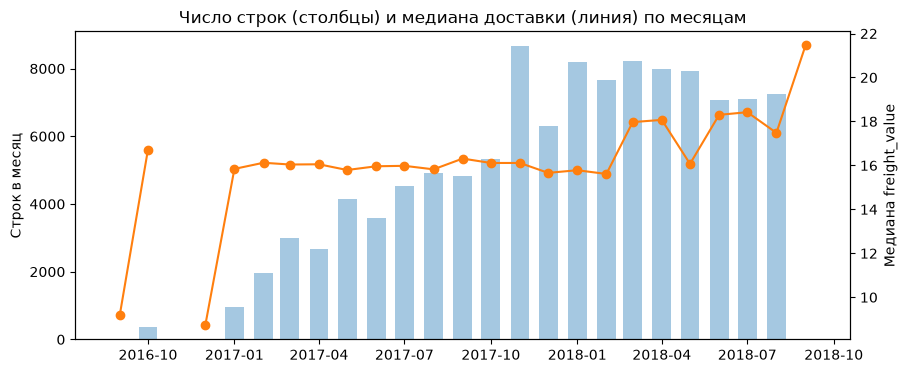

,count,median
order_purchase_timestamp,,
2016-09-01,6,9.195
2016-10-01,363,16.720
2016-11-01,0,NaN
2016-12-01,1,8.720
2017-01-01,955,15.840
2017-02-01,1951,16.120
2017-03-01,3000,16.040
2017-04-01,2684,16.050
2017-05-01,4136,15.790


In [15]:
monthly = (df.set_index('order_purchase_timestamp')[TARGET]
             .resample('MS')
             .agg(['count', 'median']))

fig, ax1 = plt.subplots()
ax1.bar(monthly.index, monthly['count'], width=20, alpha=0.4)
ax1.set_ylabel('Строк в месяц')
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['median'], color='C1', marker='o')
ax2.set_ylabel(f'Медиана {TARGET}')
plt.title('Число строк (столбцы) и медиана доставки (линия) по месяцам')
plt.show()
monthly

In [5]:
vc = df[TARGET].value_counts()
print(vc.head(20))
print(f'Топ-20 значений покрывают {vc.head(20).sum() / len(df):.1%} строк')

freight_value
15.10    3707
7.78     2262
14.10    1875
11.85    1846
18.23    1575
7.39     1521
16.11    1152
15.23    1010
8.72      921
16.79     873
14.52     848
12.79     799
10.96     723
9.34      687
17.60     601
17.67     594
12.69     575
15.11     451
12.48     436
11.73     434
Name: count, dtype: int64
Топ-20 значений покрывают 20.3% строк


**Топ-20 частых значений покрывают 20,3% строк.**
 Предположение о тарифной сетке становится более реалистичным. Любопытны близкие значения: 17,60 и 17,67. Возможных объяснений несколько: разные зоны или весовые диапазоны с близкими ценами; один и тот же тариф, слегка изменённый со временем (аналогично росту медианы freight_value в 2018 году), копеечные округления, если доставка заказа делится между несколькими товарами.

In [6]:
top = vc.head(20).index
(df[df[TARGET].isin(top)]
   .groupby(TARGET)
   .agg(n=('order_id', 'size'),
        weight_min=('product_weight_g', 'min'),
        weight_med=('product_weight_g', 'median'),
        weight_max=('product_weight_g', 'max'),
        first=('order_purchase_timestamp', 'min'),
        last=('order_purchase_timestamp', 'max'),
        sellers=('seller_id', 'nunique'))
   .sort_values('n', ascending=False))

,n,weight_min,weight_med,weight_max,first,last,sellers
freight_value,,,,,,,
15.10,3707,50.0,240.0,14600.0,2017-02-18 07:45:01,2018-06-28 09:09:32,489
7.78,2262,50.0,200.0,17500.0,2017-05-06 16:38:39,2018-08-26 04:52:35,230
14.10,1875,50.0,200.0,5600.0,2017-05-06 18:04:27,2018-08-11 22:25:58,294
11.85,1846,50.0,250.0,14850.0,2017-01-14 12:17:10,2018-08-21 08:52:46,285
18.23,1575,50.0,250.0,15225.0,2017-02-07 16:34:23,2018-08-25 07:32:25,385
7.39,1521,50.0,200.0,12050.0,2018-03-08 18:12:16,2018-08-29 10:22:35,246
16.11,1152,50.0,600.0,8500.0,2016-10-10 14:20:38,2018-08-11 22:12:54,240
15.23,1010,50.0,200.0,10000.0,2017-04-23 00:03:58,2018-08-26 21:28:46,251
8.72,921,50.0,350.0,5600.0,2016-10-04 12:53:17,2018-08-23 11:37:30,197


In [8]:
top = vc.head(30).index
sub = df[df[TARGET].isin(top)]

summary = sub.groupby(TARGET).agg(
    n=('order_id', 'size'),
    weight_med=('product_weight_g', 'median'),
    start=('order_purchase_timestamp', lambda s: s.quantile(.02)),
    end=('order_purchase_timestamp', lambda s: s.quantile(.98)),
)
summary['band'] = pd.cut(summary['weight_med'], bins=[0, 450, 1000, 2000, np.inf],
                         labels=['до 0.5 кг', '0.5–1 кг', '1–2 кг', '> 2 кг'])
summary.sort_values(['band', 'start', TARGET])

,n,weight_med,start,end,band
freight_value,,,,,
10.96,723,250.0,2016-11-18 12:54:52.960,2017-05-05 15:30:38.000,до 0.5 кг
8.72,921,350.0,2017-01-05 13:39:47.000,2018-07-17 10:56:43.400,до 0.5 кг
14.52,848,250.0,2017-01-12 08:14:41.320,2018-02-24 13:24:49.860,до 0.5 кг
15.79,415,250.0,2017-05-12 08:02:24.000,2018-07-05 08:44:23.880,до 0.5 кг
11.85,1846,250.0,2017-05-12 15:12:14.100,2018-03-01 23:41:01.900,до 0.5 кг
25.63,370,200.0,2017-05-13 05:32:12.000,2018-03-03 09:33:25.840,до 0.5 кг
15.10,3707,240.0,2017-05-13 18:27:06.480,2018-03-02 08:07:00.680,до 0.5 кг
17.63,401,200.0,2017-05-14 21:45:11.000,2018-03-31 16:10:25.000,до 0.5 кг
14.10,1875,200.0,2017-05-15 05:02:59.760,2018-03-01 17:45:52.720,до 0.5 кг


## 8. Что нельзя использовать как признаки

- `order_delivered_carrier_date`, `order_delivered_customer_date`: становятся известны только после доставки.
- `order_id`, `customer_id`: идентификаторы без информации о доставке. `order_id` нужен только для группового сплита.
- Расстояние между продавцом и покупателем, вероятно, важнейший фактор, но его пока нет в данных: нужны таблицы `customers`, `sellers`, `geolocation`.